# Anime Recomendation based on user clustering


## Introduction

Hi! On this notebook we build a anime recomendation system based on user clustering. 

We have the following available data
* User ratings on animes
* Information about the anime, like genre and type

We leverage both these informations to build our recommendation system. So lets get started!




In [1]:
#imports
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

>#### On va vérifier que ce notebook respecte bien la pipeline suivante:
>
>Data --> EDA (Exploratory Data Analysis) --> Prétraitement --> Transformation --> ML --> Evaluation

## Data preparation
First, lets import the datafiles

In [2]:
rating = pd.read_csv('./anime_recommendations_dataset/rating.csv')
rating.head(1)

,user_id,anime_id,rating
0,1,20,-1


In [3]:
anime0 = pd.read_csv('./anime_recommendations_dataset/anime.csv')
anime0.head(1)

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630


###  Pipeline : EDA (Exploratory Data Analysis) manquante
L'étape **Data** est bien présente (importation des données). Cependant, l'**EDA** a été oubliée. Avant de manipuler les caractéristiques, il faut analyser la distribution des notes, comprendre les variables et identifier les valeurs manquantes.

**Ajout d'une cellule d'EDA.**

Info ratings :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7813737 entries, 0 to 7813736
Data columns (total 3 columns):
 #   Column    Dtype
---  ------    -----
 0   user_id   int64
 1   anime_id  int64
 2   rating    int64
dtypes: int64(3)
memory usage: 178.8 MB
None

Info animes :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB
None


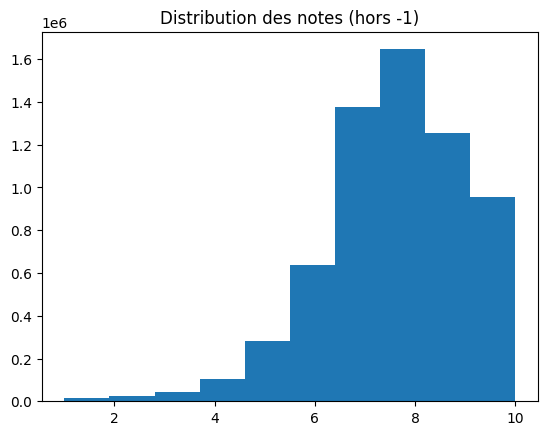

In [4]:
# EDA (Exploratory Data Analysis)
print("Info ratings :")
print(rating.info())
print("\nInfo animes :")
print(anime0.info())

# Histogramme de la distribution des notes
plt.hist(rating[rating['rating'] != -1]['rating'], bins=10)
plt.title('Distribution des notes (hors -1)')
plt.show()

L'histogramme ci-dessus est un bon début mais l'EDA reste trop légère pour justifier les choix faits plus loin (remplacement des -1, `fillna(0)`, choix des variables). On la complète avec :
- la taille du jeu de données (utilisateurs, animes, notes) et les doublons,
- la part de notes `-1` (« vu mais pas noté »),
- les valeurs manquantes de `anime.csv` (`genre`, `type`, `rating`) et les épisodes `Unknown`,
- les `anime_id` présents dans `rating.csv` mais absents de `anime.csv`,
- la distribution du nombre d'animes vus par utilisateur, la répartition des types et des genres.

Nombre de notes                : 7813737
Nombre d'utilisateurs          : 73515
Nombre d'animes notés          : 11200 / 12294 dans anime.csv
Doublons (user_id, anime_id)   : 7
Part des notes -1              : 18.9%
Lignes de rating.csv dont l'anime est absent de anime.csv : 10

Valeurs manquantes dans anime.csv :
anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

Épisodes 'Unknown' : 340

Nombre d'animes par utilisateur :
count    73515.000000
mean       106.287656
std        153.086558
min          1.000000
25%         18.000000
50%         57.000000
75%        136.000000
max      10227.000000
dtype: float64


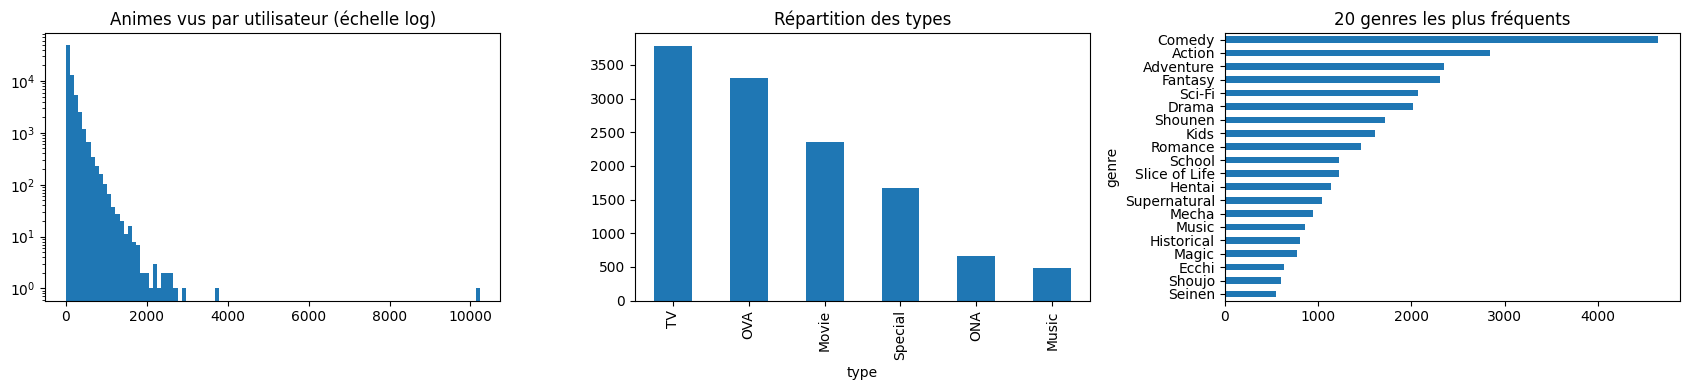

In [5]:
# EDA complémentaire
print('Nombre de notes                :', len(rating))
print("Nombre d'utilisateurs          :", rating['user_id'].nunique())
print("Nombre d'animes notés          :", rating['anime_id'].nunique(), '/', len(anime0), 'dans anime.csv')
print('Doublons (user_id, anime_id)   :', rating.duplicated(['user_id', 'anime_id']).sum())
print('Part des notes -1              : {:.1%}'.format((rating['rating'] == -1).mean()))
print('Lignes de rating.csv dont l\'anime est absent de anime.csv :',
      (~rating['anime_id'].isin(anime0['anime_id'])).sum())
print("\nValeurs manquantes dans anime.csv :")
print(anime0.isna().sum())
print("\nÉpisodes 'Unknown' :", (anime0['episodes'] == 'Unknown').sum())

nb_par_user = rating.groupby('user_id').size()
print("\nNombre d'animes par utilisateur :")
print(nb_par_user.describe())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(nb_par_user, bins=100, log=True)
axes[0].set_title("Animes vus par utilisateur (échelle log)")
anime0['type'].value_counts().plot.bar(ax=axes[1], title='Répartition des types')
genres_freq = anime0['genre'].dropna().str.split(', ').explode().value_counts()
genres_freq.head(20).plot.barh(ax=axes[2], title='20 genres les plus fréquents')
axes[2].invert_yaxis()
plt.tight_layout()
plt.show()

**Ce que l'EDA apporte pour la suite :**
- Une part importante des lignes vaut `-1` (environ 19 % sur le dataset complet). Le traitement de ces valeurs (plus bas) pèse donc lourd sur les profils utilisateurs, il faut le justifier.
- `genre` et `type` contiennent quelques valeurs manquantes. Avec le one-hot encoding, ces animes n'ont aucune caractéristique et ne contribuent pas au profil.
- Certains `anime_id` notés n'existent pas dans `anime.csv`. Après la jointure, ils n'ont que des `NaN` et sont ignorés.
- Le nombre d'animes vus par utilisateur est très asymétrique : certains en ont vu 1, d'autres plusieurs milliers. Un profil construit sur 1 ou 2 animes est peu fiable (piste d'amélioration : filtrer les utilisateurs avec trop peu de notes).
- Les genres sont très déséquilibrés (Comedy et Action dominent, Yaoi ou Cars sont rares). Cela compte pour la question de la normalisation.

On supprime les éventuels doublons (même utilisateur, même anime) avant de continuer :

In [6]:
# Prétraitement : suppression des doublons détectés pendant l'EDA
rating = rating.drop_duplicates(subset=['user_id', 'anime_id'], keep='last')

Next we will extract a feature vector for each anime

In [7]:
anime = anime0.drop(columns=['name', 'members', 'rating'])

In [8]:
# spand genre in columns, one for each genre
def func(x):
    if x['genre'] is np.nan:
        return x
    else:
        genres = list(map(lambda y: y.strip(), x['genre'].split(',')))
        for g in genres:
            x[g] = 1
        return x

anime2 = anime.apply(func, axis=1)
anime2.head(1)

,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,Super Power,Supernatural,Thriller,Vampire,Yaoi,Yuri,anime_id,episodes,genre,type
0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,32281,1,"Drama, Romance, School, Supernatural",Movie


In [9]:
# expand type in columns, one for each type
# CODE CORRIGÉ
one_hot = pd.get_dummies(anime2['type'], dtype=float).replace(0, np.nan)
anime3 = (anime2
          .drop(columns=['type', 'episodes', 'genre'])
          .join(one_hot, rsuffix='-type'))
attr = anime3.columns.drop('anime_id')
anime3[attr] = anime3[attr].astype(float)
anime3.head(1)

,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,Vampire,Yaoi,Yuri,anime_id,Movie,Music-type,ONA,OVA,Special,TV
0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,32281,1.0,NaN,NaN,NaN,NaN,NaN


### Pipeline : Prétraitement — correction du one-hot encoding
Le prétraitement des animes est présent : suppression de `name`, `members` et `rating`, éclatement des genres, one-hot du type. En revanche, le code d'origine de la cellule ci-dessus écrivait des `NaN` dans le résultat booléen de `pd.get_dummies`. Avec pandas 2, cela produit un `FutureWarning` et des colonnes de dtype `object` (`True`/`NaN`), sur lesquelles le `groupby(...).mean()` utilisé plus loin échoue. Avec pandas 3, la ligne lève directement une `TypeError`.

**Correction (appliquée dans la cellule ci-dessus) : on force un dtype numérique dès le one-hot.**

Remarque : `members` (popularité), `rating` (note moyenne) et `episodes` sont supprimés sans justification. C'est un choix de modélisation acceptable (on veut décrire les *goûts*, pas la popularité), mais il aurait dû être expliqué.

Now we can merge each anime features in the rating table

In [10]:
rating_anime = rating.join(anime3.set_index('anime_id'), on='anime_id')
rating_anime.head(1)

,user_id,anime_id,rating,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,...,Thriller,Vampire,Yaoi,Yuri,Movie,Music-type,ONA,OVA,Special,TV
0,1,20,-1,1.0,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


We have to deal with the -1 rating, which indicates that the user has watched the anime but not rated. Well, we can assume that the user hasn't rated because s/he did not have a good reason to do so (the anime was neither great, nor bad). So we assign a rating of 5 to this animes. It also help us diferenciate between the animes he has watched and not rated (which is preferable) and the ones he has not watched.

In [11]:
rating_anime['rating'] = rating_anime['rating'].replace(-1, 5)

### Pipeline : Prétraitement — hypothèse sur les `-1`
Remplacer `-1` par 5 est une **hypothèse forte et arbitraire**, sur environ 1 ligne sur 5 du dataset. Plusieurs alternatives auraient pu être comparées :
- remplacer par la **note moyenne de l'utilisateur** (certains notent tout entre 7 et 10, et pour eux 5 est une mauvaise note),
- remplacer par la note moyenne de l'anime,
- ignorer ces lignes.

Le notebook est aussi **incohérent** : plus bas, pour les recommandations, les `-1` sont ignorés au lieu d'être remplacés par 5. On garde le choix de l'auteur pour rester fidèle au notebook, mais il faudrait le valider (voir l'évaluation à la fin).

Next, the rating becomes a weight in the anime properties

In [12]:
# anime3 is the dataframe joined before.
# All columns are anime properties, except anime_id.
attr = anime3.columns.tolist()
attr.remove('anime_id')

rating_anime[attr] = rating_anime[attr].mul(rating_anime['rating'], axis=0)
rating_anime.head(10)

,user_id,anime_id,rating,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,...,Thriller,Vampire,Yaoi,Yuri,Movie,Music-type,ONA,OVA,Special,TV
0,1,20,5,5.0,NaN,NaN,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
1,1,24,5,NaN,NaN,NaN,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
2,1,79,5,NaN,NaN,NaN,5.0,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
3,1,226,5,5.0,NaN,NaN,NaN,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
4,1,241,5,NaN,NaN,NaN,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
5,1,355,5,5.0,NaN,NaN,NaN,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
6,1,356,5,5.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
7,1,442,5,NaN,5.0,NaN,5.0,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN
8,1,487,5,NaN,NaN,NaN,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
9,1,846,5,NaN,NaN,NaN,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0


Now we can calculate user preference as the mean values for its gradings in each category

In [13]:
users = (rating_anime
         .drop(columns=['anime_id', 'rating'])
         .groupby(by='user_id')
         .mean())
users.head()

,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,Thriller,Vampire,Yaoi,Yuri,Movie,Music-type,ONA,OVA,Special,TV
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.200000,5.333333,NaN,5.103093,NaN,5.714286,5.000000,5.230769,5.108696,5.833333,...,NaN,5.0,NaN,NaN,5.000000,NaN,NaN,5.000000,5.000000,5.172414
2,NaN,NaN,NaN,7.500000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.666667
3,7.218750,7.479167,NaN,7.589744,NaN,6.500000,7.451613,7.800000,7.576923,7.000000,...,8.000000,6.0,NaN,NaN,7.142857,NaN,NaN,7.000000,7.666667,7.623188
4,5.000000,5.000000,NaN,5.000000,NaN,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.0,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,5.000000
5,4.707006,5.182796,6.0,4.168712,1.0,4.200000,5.217949,2.510000,4.416667,4.100000,...,7.285714,4.5,NaN,NaN,5.846154,NaN,2.6,4.241935,4.055556,4.273846


The nan values in dataframe refers to categories that the user has never watched an anime in. So, its a good hypotesis to assign a 0 grade to then

In [14]:
users = users.fillna(value=0)
users.head()

,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,Thriller,Vampire,Yaoi,Yuri,Movie,Music-type,ONA,OVA,Special,TV
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.200000,5.333333,0.0,5.103093,0.0,5.714286,5.000000,5.230769,5.108696,5.833333,...,0.000000,5.0,0.0,0.0,5.000000,0.0,0.0,5.000000,5.000000,5.172414
2,0.000000,0.000000,0.0,7.500000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,6.666667
3,7.218750,7.479167,0.0,7.589744,0.0,6.500000,7.451613,7.800000,7.576923,7.000000,...,8.000000,6.0,0.0,0.0,7.142857,0.0,0.0,7.000000,7.666667,7.623188
4,5.000000,5.000000,0.0,5.000000,0.0,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.0,0.0,0.0,5.000000,0.0,0.0,0.000000,0.000000,5.000000
5,4.707006,5.182796,6.0,4.168712,1.0,4.200000,5.217949,2.510000,4.416667,4.100000,...,7.285714,4.5,0.0,0.0,5.846154,0.0,2.6,4.241935,4.055556,4.273846


### Pipeline : Transformation présente, mais à discuter
La transformation existe bien : chaque utilisateur est représenté par un vecteur de 49 variables (genres + types). Comme les absences valent `NaN` et que `mean()` ignore les `NaN`, chaque valeur correspond à la **note moyenne que l'utilisateur donne aux animes de ce genre**. Plusieurs points méritent d'être relevés :

1. **Perte de l'information de fréquence** : un utilisateur qui a vu 1 anime d'action noté 10 et un autre qui en a vu 200 notés 10 ont le même profil sur ce genre.
2. **`fillna(0)` mélange deux situations** : « jamais vu ce genre » reçoit 0, une valeur *inférieure* à la pire note possible (1). Le modèle interprète donc l'absence comme un rejet total.
3. **Normalisation** : aucune standardisation n'est faite avant la PCA et le K-Means. Ici, ce n'est **pas forcément une erreur**, car toutes les variables ont la même unité (une note entre 0 et 10). Un `StandardScaler` donnerait autant de poids à des genres très rares (Yaoi, Cars) qu'aux genres majeurs, et amplifierait le bruit de ces colonnes presque vides. Le choix de ne pas normaliser est défendable, mais il aurait dû être justifié.
4. **Mémoire** : la table `rating_anime` (7,8 M lignes × ~50 colonnes en `float64`) pèse plusieurs Go. Passer en `float32` diviserait cette taille par deux.

Lets evaluate how to reduce dimensionality before applying kmeans

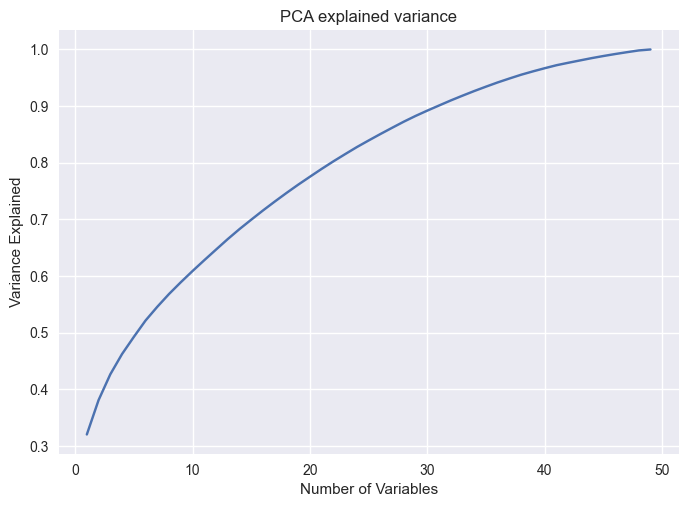

In [15]:
%matplotlib inline

pca = PCA()
pca.fit(users)
acc_var = np.cumsum(pca.explained_variance_ratio_)

plt.style.use('seaborn-v0_8')  # 'seaborn' a été renommé dans matplotlib >= 3.6
plt.plot(range(1, len(acc_var)+1), acc_var)
plt.title('PCA explained variance')
plt.xlabel('Number of Variables')
_ = plt.ylabel('Variance Explained')

Based on the plot above, we choose the number of variables. About 80% of variance explained seems good. 

In [16]:
number_of_components = 20
pca.set_params(n_components=number_of_components)
pca.fit(users)
users_pca = pca.transform(users)
users_pos_pca = pd.DataFrame(users_pca)
users_pos_pca['user_id'] = users.index
users_pos_pca = users_pos_pca.set_index('user_id')
users_pos_pca.head(1)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
user_id,,,,,,,,,,,,,,,,,,,,
1,-7.925522,2.410327,2.714332,-3.372157,0.403649,5.826858,2.412327,-0.359833,0.212623,-4.78838,2.315067,-2.271585,1.214795,0.862161,-0.002259,1.546218,-1.655697,-1.892102,-1.902188,-1.930468


### Pipeline : Transformation (PCA) — choix « à l'œil »
La réduction de dimension est bien faite, mais `number_of_components = 20` est fixé à la main, sans vérifier que l'on atteint effectivement 80 % de variance expliquée. On le vérifie directement :

In [17]:
n_80 = int(np.argmax(acc_var >= 0.80) + 1)
print(f'Composantes nécessaires pour 80 % de variance : {n_80}')
print(f'Variance expliquée avec {number_of_components} composantes : {acc_var[number_of_components - 1]:.1%}')

Composantes nécessaires pour 80 % de variance : 22
Variance expliquée avec 20 composantes : 77.5%


## K-means clustering
Now we are ready to clusterize. Kmeans is great, but you have to tell the number of nodes. We try for several number of nodes and choose based on the plot of the quadratic error. The ideia is choosing a value when the curve begins to decrease more slowly. Of course, this is not always very clear, so it is a bit subjective.

### Pipeline : ML — choix de k incomplet
Dans le code d'origine, une liste `scores = []` est déclarée mais **jamais remplie** : l'auteur semble avoir prévu un second critère (probablement le score de silhouette) sans l'implémenter. Seule la méthode du coude est utilisée, et l'auteur reconnaît lui-même qu'elle n'est « pas claire du tout ». Problèmes techniques en plus :
- `n_jobs` a été supprimé de `KMeans` (scikit-learn ≥ 1.0), donc le code d'origine plante,
- pas de `random_state`, donc les résultats ne sont pas reproductibles.

**Correction : on complète la boucle avec le score de silhouette** (calculé sur un échantillon de 10 000 utilisateurs, sinon le calcul est trop long).

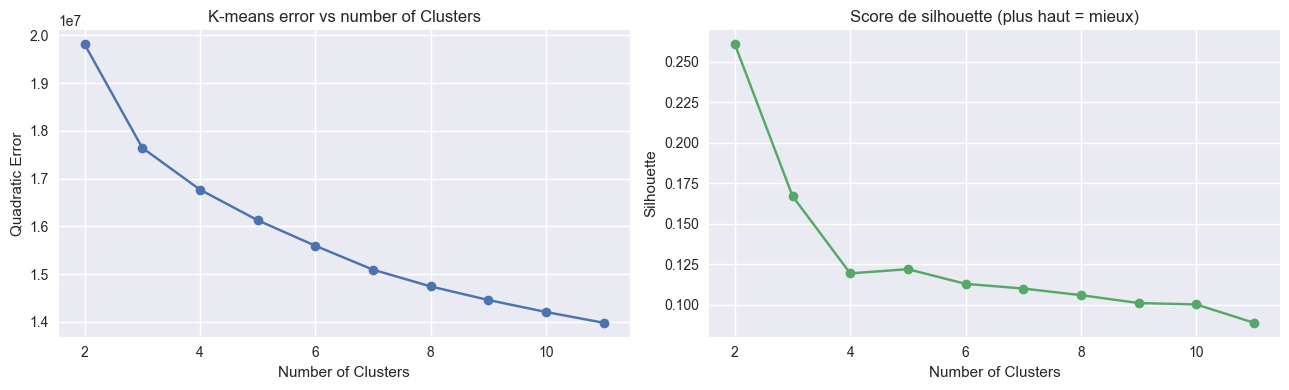

k avec la meilleure silhouette : 2


In [18]:
from sklearn.metrics import silhouette_score

inertia = []
scores = []
k_range = range(2, 12)
for n_clusters in k_range:
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    labels_k = kmeans.fit_predict(users_pos_pca)
    inertia.append(kmeans.inertia_)
    scores.append(silhouette_score(users_pos_pca, labels_k, sample_size=10000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_range, inertia, marker='o')
axes[0].set(xlabel='Number of Clusters', ylabel='Quadratic Error', title='K-means error vs number of Clusters')
axes[1].plot(k_range, scores, marker='o', color='C1')
axes[1].set(xlabel='Number of Clusters', ylabel='Silhouette', title='Score de silhouette (plus haut = mieux)')
plt.tight_layout()
plt.show()
print('k avec la meilleure silhouette :', list(k_range)[int(np.argmax(scores))])

Great, is not clear at all, but between 4 and 8 seems a good choice. We chose 6.

### Pipeline : ML — validation de la stabilité du clustering
Le K-Means n'est pas supervisé : il n'y a pas d'étiquette, donc pas de validation croisée au sens classique (cette validation est faite à la fin, sur les **recommandations**). On peut en revanche vérifier que les clusters sont **stables** : si on relance K-Means avec d'autres initialisations, retrouve-t-on les mêmes groupes ? On le mesure avec l'*Adjusted Rand Index* (ARI : 1 = partitions identiques, ~0 = partitions sans rapport).

On garde k = 6 comme l'auteur. Si la silhouette au-dessus désigne clairement un autre k, il suffit de modifier `n_clusters_final`.

In [19]:
from sklearn.metrics import adjusted_rand_score

n_clusters_final = 6

runs = [KMeans(n_clusters=n_clusters_final, n_init=10, random_state=s).fit_predict(users_pos_pca)
        for s in range(5)]
ari = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
print('ARI entre la graine 0 et les graines 1 à 4 :', np.round(ari, 3))
print(f'ARI moyen : {np.mean(ari):.3f}')

ARI entre la graine 0 et les graines 1 à 4 : [0.983 0.984 0.991 0.991]
ARI moyen : 0.987


## Clustering visualization

Now lets plot the clusters (who doesn't love 3d plots?).

To do so we need two things:
* project the users feature vector in 3 dimensions
* find each user's cluster

In [20]:
#project the users feature vector in 3 dimensions
users_with_label = pd.DataFrame(PCA(n_components=3).fit_transform(users))
users_with_label['user_id'] = users.index
users_with_label = users_with_label.set_index('user_id')

#find each user's cluster  (n_jobs supprimé de scikit-learn, random_state ajouté)
kmeans = KMeans(n_clusters=n_clusters_final, n_init=30, random_state=42)
users_with_label['label'] = kmeans.fit_predict(users_pos_pca)
users_with_label.head()

,0,1,2,label
user_id,,,,
1,-7.925522,2.410327,2.714332,2
2,-27.318069,8.940326,1.312105,4
3,5.447082,-4.407054,-2.629322,1
4,-9.340778,-0.184759,-1.601059,2
5,-5.142250,10.747538,-2.644746,2


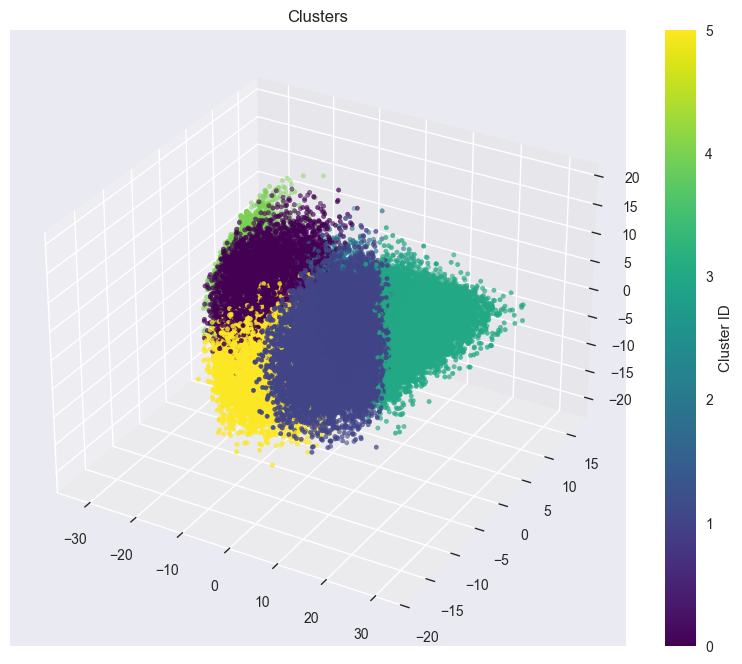

In [21]:
# Axes3D(fig) n'ajoute plus d'axes à la figure depuis matplotlib 3.4 -> add_subplot(projection='3d')
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(users_with_label[0], users_with_label[1], users_with_label[2],
                c=users_with_label['label'].to_numpy(), cmap='viridis', s=10)
plt.colorbar(sc, label='Cluster ID')
_ = plt.title('Clusters')

Awesome, we can see the clusters. It is worth to remember the clustering is done in a higher dimensional space than the plot. If you can project a 20-dimensional space in your head, you can probably see them better than that.

Is the clusters well split, though?

In [22]:
# .iteritems() a été supprimé dans pandas 2.0
print('Cluster ID     Number of users in cluster')
for idx, val in users_with_label['label'].value_counts().sort_index().items():
    print(f'{idx}              {val}')

Cluster ID     Number of users in cluster
0              8161
1              18747
2              9956
3              19267
4              8207
5              9177


I guess that is a good split

### Pipeline : Évaluation du clustering — pas d'interprétation
« I guess that is a good split » n'est pas une évaluation : des clusters de tailles équilibrées ne disent rien sur leur sens. Il manque une **interprétation des clusters**. On regarde, pour chaque cluster, les genres et types sur-représentés par rapport à la moyenne de tous les utilisateurs :

In [23]:
profil_clusters = users.join(users_with_label['label']).groupby('label').mean()
ecart = profil_clusters - users.mean()
for lab, row in ecart.iterrows():
    top = row.nlargest(5)
    print(f'Cluster {lab} ({(users_with_label["label"] == lab).sum()} utilisateurs) : '
          + ', '.join(f'{g} ({v:+.2f})' for g, v in top.items()))

Cluster 0 (8161 utilisateurs) : Comedy (+0.54), Fantasy (+0.53), Romance (+0.47), Action (+0.39), TV (+0.33)
Cluster 1 (18747 utilisateurs) : Horror (+1.64), Seinen (+1.64), Thriller (+1.59), Military (+1.57), Psychological (+1.57)
Cluster 2 (9956 utilisateurs) : Dementia (+0.63), ONA (+0.53), Josei (+0.37), Music (+0.37), Space (+0.36)
Cluster 3 (19267 utilisateurs) : Space (+3.46), Samurai (+3.35), Music (+3.24), ONA (+3.16), Sports (+3.05)
Cluster 4 (8207 utilisateurs) : TV (-0.31), Yuri (-0.34), Yaoi (-0.41), Cars (-0.75), Hentai (-0.80)
Cluster 5 (9177 utilisateurs) : Thriller (+1.95), Psychological (+1.88), Police (+1.49), Mystery (+1.46), Supernatural (+0.93)


## Create the recomendations.

We need to evaluate what is a good anime chosen by the group. There are two important factor, average rating and views (Spoiler: I will multiply then together to build a single score).

First, we join to the rating table the user's cluster.

Differently from before, when the rating assinged is -1, we will ignore it, since we already know the groups and we have a lot of good, non-guessed, ratings.

In [24]:
rating_user = rating.join(users_with_label[['label']], on='user_id')
rating_user.loc[rating_user['rating'] == -1, 'rating'] = np.nan
rating_user.head(1)

,user_id,anime_id,rating,label
0,1,20,NaN,2


Group the data so we can get the mean rating and the view count for each anime in each user cluster

In [25]:
groups = (rating_user[['anime_id', 'rating', 'label']]
          .groupby(by=['label', 'anime_id'])
          .rating.agg(['mean', 'count']))
groups.head(2)

mean  count
label anime_id                 
0     1         9.075758    264
      5         8.500000     68

Our goodness evaluation (obj - stands for objective) is the mean rating multiplied by the view count.

In [26]:
groups['obj'] = groups['mean']*groups['count']
groups.head()

mean  count     obj
label anime_id                         
0     1         9.075758    264  2396.0
      5         8.500000     68   578.0
      6         8.768182    220  1929.0
      7         7.571429     14   106.0
      8         7.500000      6    45.0

if some anime has received no evaluation for some user cluster, obj will be nan. We have so much anime to recomend... just drop those that are nan and we should be fine

In [27]:
groups_obj = groups[['obj']].dropna()
groups_obj.head(2)

obj
label anime_id        
0     1         2396.0
      5          578.0

Reorganize this information sorting, for each user cluster, the animes by obj. Replace anime_id by their names and organize everything on a dataframe

In [28]:
cats = groups_obj.index.get_level_values(0).unique().tolist()
rec = []
for cat in cats:
    rec.append(
        groups_obj
        .loc[cat]
        .sort_values(by='obj', ascending=False)
        .reset_index()
        .join(
            anime0[['name', 'anime_id']].set_index('anime_id'),
            on='anime_id')
        ['name']
        .rename(cat)
    )
rec = pd.concat(rec, axis=1)
rec.head(10)

,0,1,2,3,4,5
0,Ouran Koukou Host Club,Death Note,Death Note,Death Note,Death Note,Death Note
1,Sword Art Online,Sword Art Online,Code Geass: Hangyaku no Lelouch,Code Geass: Hangyaku no Lelouch,Naruto,Shingeki no Kyojin
2,Naruto,Shingeki no Kyojin,Angel Beats!,Code Geass: Hangyaku no Lelouch R2,Sword Art Online,Sword Art Online
3,Angel Beats!,Code Geass: Hangyaku no Lelouch,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood,Shingeki no Kyojin,Fullmetal Alchemist: Brotherhood
4,Shingeki no Kyojin,Angel Beats!,Sen to Chihiro no Kamikakushi,Toradora!,Ouran Koukou Host Club,Naruto
5,Fullmetal Alchemist,Fullmetal Alchemist: Brotherhood,Shingeki no Kyojin,Angel Beats!,Angel Beats!,Elfen Lied
6,Toradora!,Elfen Lied,Code Geass: Hangyaku no Lelouch R2,Shingeki no Kyojin,Dragon Ball Z,Code Geass: Hangyaku no Lelouch
7,Sen to Chihiro no Kamikakushi,Code Geass: Hangyaku no Lelouch R2,Tengen Toppa Gurren Lagann,Elfen Lied,Sen to Chihiro no Kamikakushi,Mirai Nikki (TV)
8,Clannad,Naruto,Neon Genesis Evangelion,Fullmetal Alchemist,Vampire Knight,Fullmetal Alchemist
9,Fullmetal Alchemist: Brotherhood,Mirai Nikki (TV),Fullmetal Alchemist,Sword Art Online,Clannad,Angel Beats!


A lot (really lot) of animes repeat between clusters. Well, that is reasonable, since the most popular animes can be liked by everyone. But, if all recomendations are the same, this is the most useless code of all times. Lets measure how much variability exists between the lists. I find that a good measure is to count unique values overall. If we have more unique values on a fixed lenght list, we have more differences between clusters, as some anime are suggested for one cluster and not for another

In [29]:
# np.unique plante si un anime_id recommandé est absent de anime.csv (nom = NaN mélangé à des str)
# -> pd.unique, qui gère les types mélangés
for i in range(2, 20, 2):
    print('First {} recomendations: {} animes in total'
          .format(
              i,
              pd.unique(
                  rec
                  .head(i)
                  .to_numpy()
                  .ravel())
              .shape[0]))

First 2 recomendations: 6 animes in total
First 4 recomendations: 9 animes in total
First 6 recomendations: 13 animes in total
First 8 recomendations: 16 animes in total
First 10 recomendations: 19 animes in total
First 12 recomendations: 24 animes in total
First 14 recomendations: 31 animes in total
First 16 recomendations: 33 animes in total
First 18 recomendations: 36 animes in total


We find that we do have a good variability, so the recomendation system works

### Pipeline : Évaluation insuffisante et validation croisée absente
La conclusion « the recomendation system works » n'est pas démontrée :
1. Le nombre d'animes distincts mesure la **diversité** entre clusters, pas la **qualité** des recommandations. Des listes aléatoires différentes par cluster auraient une diversité maximale.
2. Le score `obj = moyenne × nombre de vues` revient à la **somme des notes** : il favorise surtout les animes populaires. C'est ce qui explique les nombreuses répétitions entre clusters.
3. Les animes **déjà vus** par l'utilisateur ne sont pas retirés de ses recommandations.
4. Il n'y a **ni jeu de test, ni validation croisée, ni modèle de référence** (baseline) pour comparer.

**Ajout d'une évaluation hors-ligne avec validation croisée (K-Fold) :**
- on découpe les notes en 3 folds. À chaque fold, les notes du fold servent de **test** et le reste d'**entraînement** (les `-1` restent toujours dans l'entraînement, car ils ne disent pas si l'anime a plu),
- on refait **toute la chaîne sur l'entraînement uniquement** (profils, PCA, K-Means, classement par cluster) pour éviter les fuites de données,
- on recommande à chaque utilisateur les 10 meilleurs animes de son cluster **qu'il n'a pas encore vus**,
- un anime du test noté ≥ 8 est considéré comme « aimé ». On calcule la `precision@10`, le `recall@10` et le `hit_rate@10` (au moins un anime aimé dans le top 10),
- on compare à une **baseline de popularité** : le même score `obj` calculé sur tous les utilisateurs, sans clustering.

Pour garder un temps de calcul raisonnable, l'évaluation se fait sur un sous-échantillon aléatoire d'utilisateurs (`N_USERS_EVAL`).

In [30]:
from sklearn.model_selection import KFold

N_USERS_EVAL = 15000     # sous-échantillon d'utilisateurs (augmenter si la machine le permet)
N_FOLDS = 3
TOP_K = 10
LIKE_THRESHOLD = 8       # note >= 8 dans le test = anime aimé
N_CANDIDATES = 300       # taille des listes classées avant filtrage des animes déjà vus

feat = anime3.set_index('anime_id')
attr_cols = feat.columns.tolist()


def build_user_profiles(ratings):
    # Même transformation que plus haut : -1 -> 5, note comme poids, moyenne par utilisateur, NaN -> 0
    r = ratings.copy()
    r.loc[r['rating'] == -1, 'rating'] = 5
    ra = r.join(feat, on='anime_id')
    ra[attr_cols] = ra[attr_cols].mul(ra['rating'], axis=0)
    prof = ra.drop(columns=['anime_id', 'rating']).groupby('user_id').mean()
    return prof.reindex(columns=attr_cols).fillna(0)


def fit_clusters(profiles, n_components, n_clusters, seed):
    X = PCA(n_components=n_components, random_state=seed).fit_transform(profiles)
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit_predict(X)
    return pd.Series(labels, index=profiles.index, name='label')


def rank_by_cluster(ratings, labels):
    # Même score que le notebook : obj = moyenne * nombre de notes, par cluster
    r = ratings[ratings['rating'] != -1].join(labels, on='user_id')
    g = r.groupby(['label', 'anime_id'])['rating'].agg(['mean', 'count'])
    g['obj'] = g['mean'] * g['count']
    return {lab: grp.droplevel(0)['obj'].nlargest(N_CANDIDATES).index.tolist()
            for lab, grp in g.groupby(level=0)}


def rank_global(ratings):
    # Baseline : même score mais sans clustering (popularité globale)
    g = ratings[ratings['rating'] != -1].groupby('anime_id')['rating'].agg(['mean', 'count'])
    return (g['mean'] * g['count']).nlargest(N_CANDIDATES).index.tolist()


def top_k_unseen(candidates, seen, k):
    out = []
    for a in candidates:
        if a not in seen:
            out.append(a)
            if len(out) == k:
                break
    return out


def evaluate(train, test, labels):
    cluster_rank = rank_by_cluster(train, labels)
    global_rank = rank_global(train)
    seen = train.groupby('user_id')['anime_id'].agg(set)
    liked = test[test['rating'] >= LIKE_THRESHOLD].groupby('user_id')['anime_id'].agg(set)
    res = {'clustering': [], 'popularite (baseline)': []}
    for uid, liked_set in liked.items():
        if uid not in labels.index:
            continue
        s = seen.get(uid, set())
        for name, cands in (('clustering', cluster_rank.get(labels[uid], [])),
                            ('popularite (baseline)', global_rank)):
            hits = len(liked_set.intersection(top_k_unseen(cands, s, TOP_K)))
            res[name].append((hits / TOP_K, hits / len(liked_set), hits > 0))
    return {name: np.mean(v, axis=0) for name, v in res.items()}


rng = np.random.default_rng(42)
all_users = rating['user_id'].unique()
users_eval = rng.choice(all_users, size=min(N_USERS_EVAL, len(all_users)), replace=False)
sub = rating[rating['user_id'].isin(users_eval)]
unrated = sub[sub['rating'] == -1]
rated = sub[sub['rating'] != -1].reset_index(drop=True)

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
rows = []
for fold, (tr_idx, te_idx) in enumerate(kf.split(rated), start=1):
    train = pd.concat([rated.iloc[tr_idx], unrated])
    test = rated.iloc[te_idx]
    profiles = build_user_profiles(train)
    labels = fit_clusters(profiles, number_of_components, n_clusters_final, seed=fold)
    for name, (p, r, h) in evaluate(train, test, labels).items():
        rows.append({'fold': fold, 'modele': name,
                     f'precision@{TOP_K}': p, f'recall@{TOP_K}': r, f'hit_rate@{TOP_K}': h})
    print(f'Fold {fold}/{N_FOLDS} terminé')

cv_results = pd.DataFrame(rows)
cv_results.drop(columns='fold').groupby('modele').agg(['mean', 'std']).round(4)

Fold 1/3 terminé
Fold 2/3 terminé
Fold 3/3 terminé


precision@10         recall@10         hit_rate@10  \
                              mean     std      mean     std        mean   
modele                                                                     
clustering                  0.1552  0.0011    0.1166  0.0014      0.6551   
popularite (baseline)       0.1533  0.0001    0.1181  0.0020      0.6566   

                               
                          std  
modele                         
clustering             0.0045  
popularite (baseline)  0.0012

**Lecture des résultats :** si le modèle par clustering n'obtient pas de meilleures métriques que la baseline de popularité, le clustering n'apporte rien de plus que de recommander les animes les plus populaires. Un écart-type faible entre les folds indique un résultat stable. Ce tableau permet enfin de **justifier** (ou non) l'affirmation « the recomendation system works », et de comparer objectivement d'autres choix : valeur de k, remplacement des `-1`, normalisation, etc.

## Bilan de la vérification de la pipeline

| Étape | Présente dans le notebook d'origine ? | Remarques / ajouts |
|---|---|---|
| **Data** | Oui | Chargement de `rating.csv` et `anime.csv`. |
| **EDA** | **Non** | Ajoutée : distribution des notes, part des `-1`, valeurs manquantes, doublons, animes inconnus, activité des utilisateurs, types et genres. |
| **Prétraitement** | Partiel | One-hot des genres/types et gestion des `-1` présents. Corrigé : dtype du one-hot (bug avec pandas récent), doublons. Hypothèse `-1 → 5` arbitraire et incohérente avec la partie recommandation. |
| **Transformation** | Oui | Profils utilisateurs (note moyenne par genre/type) puis PCA. Discuté : perte de la fréquence, `fillna(0)` < note minimale, absence de normalisation (défendable ici), nombre de composantes non vérifié (vérification ajoutée). |
| **ML** | Partiel | K-Means présent, k choisi au coude de façon subjective, `scores` jamais calculé. Ajouté : silhouette, stabilité (ARI), `random_state`. Corrigé : `n_jobs`, `Axes3D`, `iteritems`, style `seaborn`, `np.unique` sur des noms manquants. |
| **Évaluation** | **Non** (diversité seulement) | Ajouté : interprétation des clusters, évaluation hors-ligne par **validation croisée K-Fold** (precision/recall/hit-rate@10) comparée à une baseline de popularité, avec exclusion des animes déjà vus. |

# Cheers!
If you like this notebook, don't forget to leave an upvote :)